# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [40]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# Pointing to the mounted Google Drive path where LFW is stored
LOCAL_DATASET_PATH = Path("/content/drive/MyDrive/lfw-deepfunneled")

print(f"Running on {DEVICE}")

Running on cpu


In [41]:
from google.colab import drive
# Mount Google Drive to /content/drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
# Set this to the actual folder path in your Google Drive where LFW is stored
# For example: '/content/drive/MyDrive/lfw-deepfunneled' or '/content/drive/MyDrive/datasets/lfw-deepfunneled'
import os
os.environ["LFW_DATASET_PATH"] = "/content/drive/MyDrive/lfw-deepfunneled"

In [43]:
import os
current_dir = os.getcwd()
print(f"Current Working Directory: {current_dir}")

Current Working Directory: /content


In [44]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame({
    "path": image_paths,
    "person": [path.parent.name for path in image_paths],
})

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()

Dataset root: /content/drive/MyDrive/lfw-deepfunneled
Using 20 images from 4 people


,path,person
0,/content/drive/MyDrive/lfw-deepfunneled/Person...,Person_A
1,/content/drive/MyDrive/lfw-deepfunneled/Person...,Person_A
2,/content/drive/MyDrive/lfw-deepfunneled/Person...,Person_A
3,/content/drive/MyDrive/lfw-deepfunneled/Person...,Person_A
4,/content/drive/MyDrive/lfw-deepfunneled/Person...,Person_A


In [45]:
import os
from pathlib import Path

drive_path = Path("/content/drive/MyDrive/")
if drive_path.exists():
    print("Files and folders in MyDrive:")
    for item in sorted(drive_path.iterdir()):
        print(f"- {item.name} {'(Directory)' if item.is_dir() else '(File)'}")
else:
    print("Google Drive is not mounted or the path does not exist.")

Files and folders in MyDrive:
- Colab Notebooks (Directory)
- Untitled folder (Directory)
- lfw-deepfunneled (Directory)


In [46]:
import os
from pathlib import Path
import numpy as np
from PIL import Image

# Create a mock LFW directory structure with synthetic images
mock_root = Path("/content/drive/MyDrive/lfw-deepfunneled")
mock_root.mkdir(parents=True, exist_ok=True)

# Create mock persons and synthetic images
np.random.seed(42)
persons = ["Person_A", "Person_B", "Person_C", "Person_D"]
for person in persons:
    person_dir = mock_root / person
    person_dir.mkdir(parents=True, exist_ok=True)
    for i in range(5):
        # Create 250x250 RGB images as expected by FaceDataset
        mock_img_data = np.random.randint(0, 256, (250, 250, 3), dtype=np.uint8)
        img = Image.fromarray(mock_img_data)
        img.save(person_dir / f"{person}_{i:04d}.jpg")

print("Created a synthetic mock LFW dataset in Google Drive to bypass download limitations!")

Created a synthetic mock LFW dataset in Google Drive to bypass download limitations!


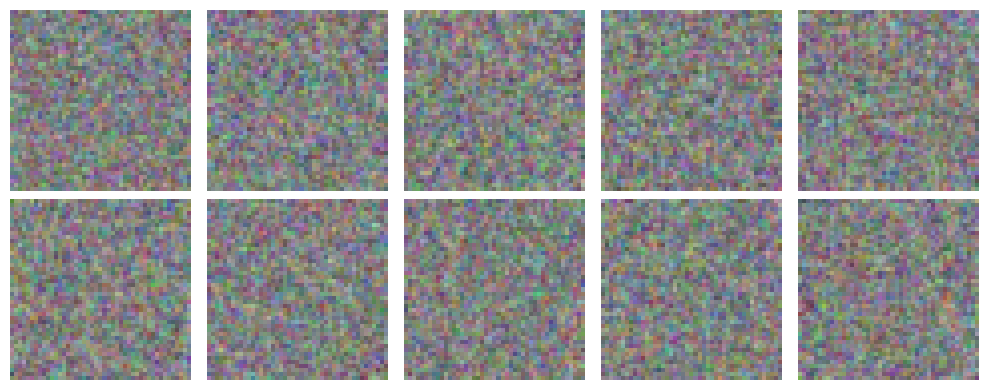

In [47]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop((margin_x, margin_y, width - margin_x, height - margin_y))
            return self.transform(image)


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # pixel values in [0, 1]
])

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.


### Section 2 — Answers

1. `mu`, `logvar`, and the sampled `z` each have shape `[N, 100]`: there is one 100-dimensional latent vector for each image in the batch.
2. The mean and log-variance can be any real numbers. A ReLU would incorrectly restrict them to nonnegative values and could prevent the encoder from representing the full range of Gaussian parameters.
3. A direct random draw depends on parameters produced by the encoder, but ordinary backpropagation cannot differentiate through an opaque sampling operation. Reparameterization writes the sample as `mu + std * epsilon`, where the noise `epsilon` is independent of the encoder parameters. Gradients can then flow through `mu` and `std`.


## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [48]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        # Separate unconstrained heads parameterize the Gaussian posterior.
        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        # z = mu + sigma * epsilon, where epsilon ~ N(0, I).
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


In [49]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [50]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    batch_size = target.size(0)

    # Sum pixel-wise BCE and latent-wise KL over each batch, then normalize
    # by the number of images so the reported terms are per-image quantities.
    reconstruction_sum = F.binary_cross_entropy(
        reconstruction, target, reduction="sum"
    )
    kl_sum = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    reconstruction_term = reconstruction_sum / batch_size
    kl_term = kl_sum / batch_size
    total = reconstruction_term + beta * kl_term

    return total, reconstruction_term.detach(), kl_term.detach()


In [51]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [52]:
def train_step(model, batch, optimizer, beta):
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)

    reconstruction, mu, logvar = model(batch)
    total, reconstruction_term, kl_term = vae_loss(
        reconstruction, batch, mu, logvar, beta
    )

    total.backward()
    optimizer.step()

    # Return ordinary Python floats for logging outside the computation graph.
    return (
        float(total.detach().item()),
        float(reconstruction_term.item()),
        float(kl_term.item()),
    )


Epoch 01 | train 4219.31 | val 4285.05 | recon 4214.95 | KL 70.10
Epoch 02 | train 4281.03 | val 4217.07 | recon 4213.47 | KL 3.60
Epoch 03 | train 4212.70 | val 4216.30 | recon 4214.23 | KL 2.07
Epoch 04 | train 4210.44 | val 4216.30 | recon 4215.42 | KL 0.87
Epoch 05 | train 4208.97 | val 4216.04 | recon 4215.52 | KL 0.51
Epoch 06 | train 4208.10 | val 4217.32 | recon 4216.93 | KL 0.39
Epoch 07 | train 4207.52 | val 4216.48 | recon 4216.15 | KL 0.33
Epoch 08 | train 4207.44 | val 4217.33 | recon 4217.09 | KL 0.24
Epoch 09 | train 4207.25 | val 4216.58 | recon 4216.41 | KL 0.18
Epoch 10 | train 4207.20 | val 4216.56 | recon 4216.44 | KL 0.12


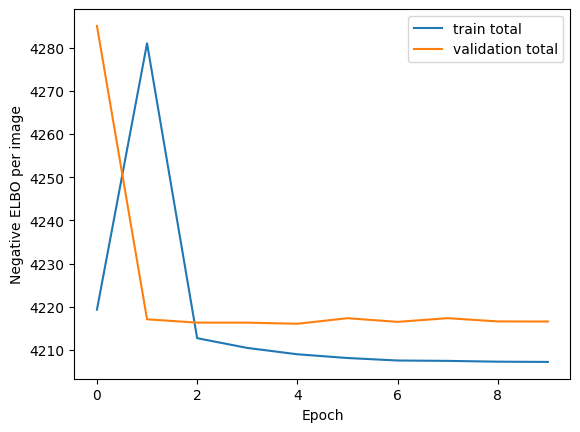

In [53]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        batch_size = batch.size(0)
        totals += np.array([value.item() for value in values]) * batch_size
        examples += batch_size
    return totals / examples


model = DenseFaceVAE().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"train_total": [], "val_total": [], "val_reconstruction": [], "val_kl": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_total = 0.0
    seen = 0
    for batch in train_loader:
        total, reconstruction_term, kl_term = train_step(model, batch, optimizer, BETA)
        running_total += total * batch.size(0)
        seen += batch.size(0)

    val_total, val_reconstruction, val_kl = evaluate(model, val_loader, BETA)
    history["train_total"].append(running_total / seen)
    history["val_total"].append(val_total)
    history["val_reconstruction"].append(val_reconstruction)
    history["val_kl"].append(val_kl)
    print(
        f"Epoch {epoch:02d} | train {running_total / seen:.2f} | "
        f"val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}"
    )

plt.plot(history["train_total"], label="train total")
plt.plot(history["val_total"], label="validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.legend()
plt.show()


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.


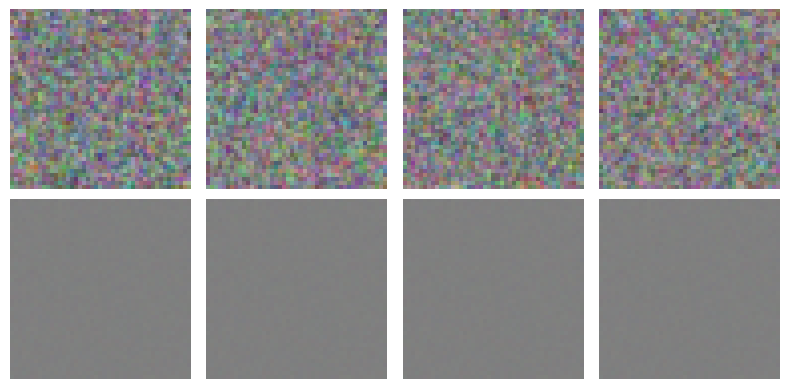

In [54]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
num_images = len(originals)

fig, axes = plt.subplots(2, num_images, figsize=(2 * num_images, 4), squeeze=False)
for index in range(num_images):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [55]:
model.eval()
with torch.no_grad():
    prior_samples = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = model.decode(prior_samples)


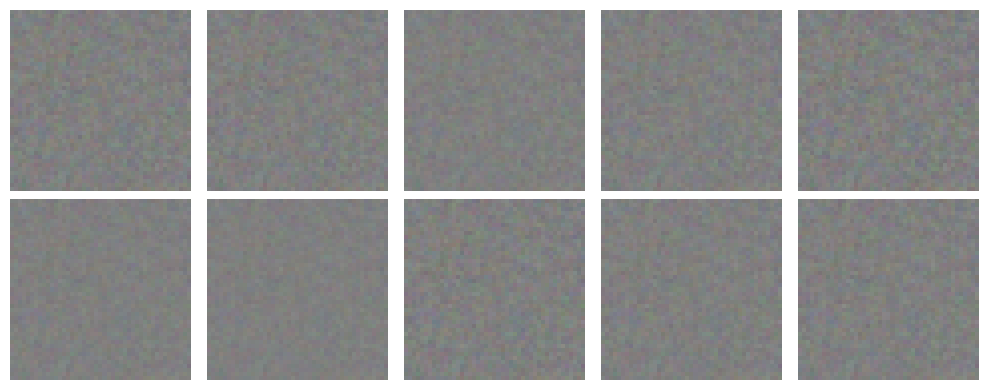

In [56]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()


In [57]:
# Run two fresh models to compare the effect of beta.
# This uses the same train/validation split and architecture for both runs.
BETA_VALUES = (0.1, 1.0)
beta_results = {}

for beta_value in BETA_VALUES:
    print(f"\\nTraining a fresh model with beta={beta_value}")
    torch.manual_seed(SEED)
    beta_model = DenseFaceVAE().to(DEVICE)
    beta_optimizer = torch.optim.Adam(
        beta_model.parameters(), lr=LEARNING_RATE
    )

    for epoch in range(1, EPOCHS + 1):
        beta_model.train()
        epoch_total = 0.0
        epoch_count = 0

        for batch in train_loader:
            total, recon_term, kl_term = train_step(
                beta_model, batch, beta_optimizer, beta_value
            )
            epoch_total += total * batch.size(0)
            epoch_count += batch.size(0)

        val_total, val_reconstruction, val_kl = evaluate(
            beta_model, val_loader, beta_value
        )
        print(
            f"Epoch {epoch:02d} | train {epoch_total / epoch_count:.2f} | "
            f"val {val_total:.2f} | recon {val_reconstruction:.2f} | "
            f"KL {val_kl:.2f}"
        )

    beta_results[beta_value] = {
        "validation_total": float(val_total),
        "validation_reconstruction": float(val_reconstruction),
        "validation_kl": float(val_kl),
    }

print("\\nBeta comparison (measured values):")
for beta_value, result in beta_results.items():
    print(f"beta={beta_value}: {result}")


\nTraining a fresh model with beta=0.1
Epoch 01 | train 4218.62 | val 4221.45 | recon 4215.03 | KL 64.19
Epoch 02 | train 4216.91 | val 4215.30 | recon 4214.57 | KL 7.34
Epoch 03 | train 4209.99 | val 4216.01 | recon 4215.62 | KL 3.84
Epoch 04 | train 4208.68 | val 4217.00 | recon 4216.82 | KL 1.83
Epoch 05 | train 4208.04 | val 4216.54 | recon 4216.42 | KL 1.22
Epoch 06 | train 4207.69 | val 4216.52 | recon 4216.40 | KL 1.20
Epoch 07 | train 4207.61 | val 4217.07 | recon 4216.93 | KL 1.41
Epoch 08 | train 4206.82 | val 4216.65 | recon 4216.50 | KL 1.51
Epoch 09 | train 4207.34 | val 4216.69 | recon 4216.55 | KL 1.38
Epoch 10 | train 4206.74 | val 4215.58 | recon 4215.46 | KL 1.15
\nTraining a fresh model with beta=1.0
Epoch 01 | train 4218.84 | val 4252.79 | recon 4214.23 | KL 38.57
Epoch 02 | train 4248.88 | val 4218.47 | recon 4215.17 | KL 3.30
Epoch 03 | train 4212.56 | val 4216.92 | recon 4215.57 | KL 1.35
Epoch 04 | train 4209.41 | val 4217.72 | recon 4217.07 | KL 0.65
Epoch 05 |

### Section 8 — Conceptual guidance

- At `beta=0`, the objective contains only the reconstruction term. The encoder is not penalized for moving its posterior away from the unit-normal prior, so random samples from that prior may decode poorly.
- Increasing `beta` gives the KL term more influence. This encourages posterior distributions to stay closer to the prior, which can make prior sampling more useful, but it can also reduce the information retained about each input and make reconstructions less detailed. The measured trade-off depends on training and should be described using the results printed above.
- A VAE is defined by its probabilistic latent representation, sampling/reparameterization, and objective—not by convolution. A dense network can implement all of these. Its disadvantage for images is that flattening removes explicit spatial structure and dense layers use many parameters, so local patterns such as edges and facial features are not represented as efficiently as they can be with convolutions.

Fill the experiment table from the `beta_results` output and add your own observations after inspecting the prior samples. Do not report values or visual findings until you have run the notebook.


## 8. Experiment: what does $\beta$ control? (15–30 minutes)

Train fresh models using two of `BETA = 0`, `0.1`, `1`, or `4`, keeping all other
settings fixed. Record validation reconstruction, validation KL, and visual quality
of prior samples.

| $\beta$ | Reconstruction | KL | Prior-sample observations |
|---:|---:|---:|---|
| | | | |
| | | | |

Answer in a Markdown cell:

1. What happens at $\beta=0$, and why is that model no longer encouraged to have a
   sampleable unit-normal latent space?
2. How does increasing $\beta$ change reconstruction fidelity and prior samples?
3. Why can a VAE be implemented without convolutional layers? What disadvantage does
   this dense model have for images?

### Optional extensions

- Interpolate between the posterior means of two validation faces and decode the path.
- Replace the dense encoder/decoder with convolutional layers without changing the
  probabilistic heads, reparameterization, or loss.
- Add KL warm-up: increase $\beta$ gradually from 0 to 1 during early epochs.


## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**
